In [19]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score,
    roc_curve
)


In [20]:
RESULTS_DIR = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\notebooks\results"
print("Using results from:", RESULTS_DIR)


Using results from: C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\notebooks\results


In [21]:
def compute_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    TPR = tp / (tp + fn)
    FPR = fp / (fp + tn)
    AUROC = roc_auc_score(y_true, y_prob)
    return TPR, FPR, AUROC


In [22]:
y_test = np.load(f"{RESULTS_DIR}/swinS_y_test.npy")
y_pred = np.load(f"{RESULTS_DIR}/swinS_y_pred.npy")
y_prob = np.load(f"{RESULTS_DIR}/swinS_y_prob.npy")

train_logloss = np.load(f"{RESULTS_DIR}/swinS_train_logloss.npy")
val_logloss   = np.load(f"{RESULTS_DIR}/swinS_val_logloss.npy")

print("Loaded Swin-S results ✅")


Loaded Swin-S results ✅


In [23]:
TPR, FPR, AUROC = compute_metrics(y_test, y_pred, y_prob)

print("MobileViT + Swin-S + XGBoost RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("TPR (Sensitivity):", TPR)
print("FPR:", FPR)
print("AUROC:", AUROC)

print(classification_report(y_test, y_pred))


MobileViT + Swin-S + XGBoost RESULTS
Accuracy: 0.9438040345821326
TPR (Sensitivity): 0.9393939393939394
FPR: 0.052562417871222074
AUROC: 0.98637526799917
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       761
           1       0.94      0.94      0.94       627

    accuracy                           0.94      1388
   macro avg       0.94      0.94      0.94      1388
weighted avg       0.94      0.94      0.94      1388



In [24]:
TPR, FPR, AUROC = compute_metrics(y_test, y_pred, y_prob)

print("MobileViT + Swin-S + XGBoost RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("TPR (Sensitivity):", TPR)
print("FPR:", FPR)
print("AUROC:", AUROC)

print(classification_report(y_test, y_pred))


MobileViT + Swin-S + XGBoost RESULTS
Accuracy: 0.9438040345821326
TPR (Sensitivity): 0.9393939393939394
FPR: 0.052562417871222074
AUROC: 0.98637526799917
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       761
           1       0.94      0.94      0.94       627

    accuracy                           0.94      1388
   macro avg       0.94      0.94      0.94      1388
weighted avg       0.94      0.94      0.94      1388



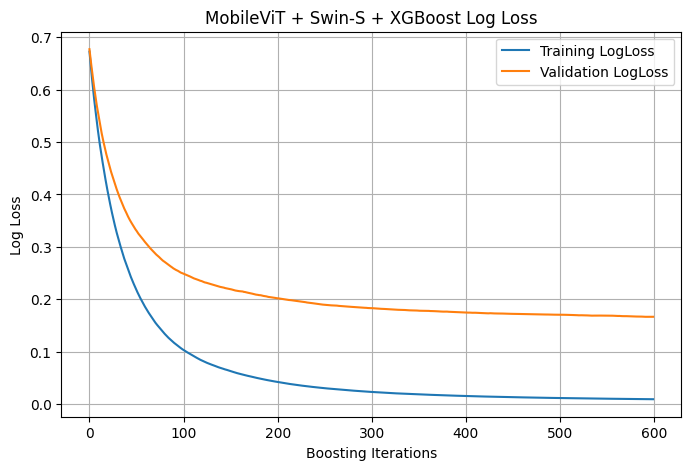

In [25]:
plt.figure(figsize=(8,5))
plt.plot(train_logloss, label="Training LogLoss")
plt.plot(val_logloss, label="Validation LogLoss")
plt.xlabel("Boosting Iterations")
plt.ylabel("Log Loss")
plt.title("MobileViT + Swin-S + XGBoost Log Loss")
plt.legend()
plt.grid(True)
plt.show()


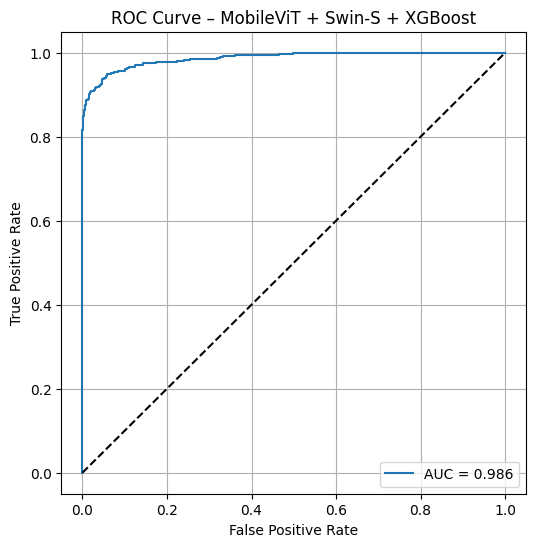

In [26]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {AUROC:.3f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – MobileViT + Swin-S + XGBoost")
plt.legend()
plt.grid(True)
plt.show()


In [27]:
print("===== FINAL TEST METRICS =====")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"TPR      : {TPR:.4f}")
print(f"FPR      : {FPR:.4f}")
print(f"AUROC    : {AUROC:.4f}")


===== FINAL TEST METRICS =====
Accuracy : 0.9438
TPR      : 0.9394
FPR      : 0.0526
AUROC    : 0.9864


In [29]:
# ===============================
# MobileViT + Swin-B + XGBoost
# ===============================

y_test_B = np.load(f"{RESULTS_DIR}/swinB_y_test.npy")
y_pred_B = np.load(f"{RESULTS_DIR}/swinB_y_pred.npy")
y_prob_B = np.load(f"{RESULTS_DIR}/swinB_y_prob.npy")

TPR_B, FPR_B, AUROC_B = compute_metrics(y_test_B, y_pred_B, y_prob_B)

print("MobileViT + Swin-B + XGBoost RESULTS")
print("Accuracy:", accuracy_score(y_test_B, y_pred_B))
print("TPR:", TPR_B)
print("FPR:", FPR_B)
print("AUROC:", AUROC_B)

print(classification_report(y_test_B, y_pred_B))


MobileViT + Swin-B + XGBoost RESULTS
Accuracy: 0.9344380403458213
TPR: 0.9218500797448166
FPR: 0.05519053876478318
AUROC: 0.9795304172508682
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       761
           1       0.93      0.92      0.93       627

    accuracy                           0.93      1388
   macro avg       0.93      0.93      0.93      1388
weighted avg       0.93      0.93      0.93      1388



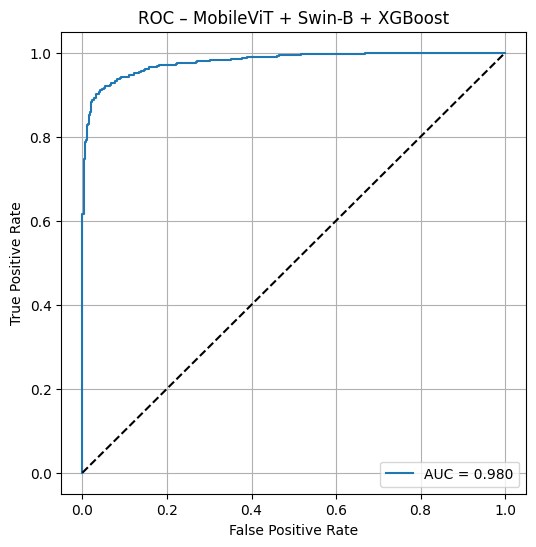

: 

In [ ]:
from sklearn.metrics import roc_curve

fprB, tprB, _ = roc_curve(y_test_B, y_prob_B)

plt.figure(figsize=(6,6))
plt.plot(fprB, tprB, label=f"AUC = {AUROC_B:.3f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC – MobileViT + Swin-B + XGBoost")
plt.legend()
plt.grid(True)
plt.show()
